In [2]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [10]:
data = {
'Age':  ['Youth', 'Youth', 'Middle', 'Senior', 'Senior', 'Middle', 'Senior', 'Youth', 'Youth', 'Senior', 'Youth', 'Middle', 'Middle', 'Senior'],
'Income': ['High', 'High', 'High', 'Medium', 'Low', 'Low', 'Low', 'Medium', 'Low', 'Medium', 'Medium', 'Medium', 'High', 'Medium'],
'Student':['No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No'],
'CreditRating':['Fair', 'Excellent', 'Fair', 'Fair', 'Fair', 'Excellent', 'Excellent', 'Fair', 'Fair', 'Fair', 'Excellent', 'Excellent', 'Fair', 'Excellent'],
'BuysComputer':['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
}

In [7]:
df = pd.DataFrame(data)

In [8]:
df

,Age,Income,Student,CreditRating,BuysComputer
0,Youth,High,No,Fair,No
1,Youth,High,No,Excellent,No
2,Middle,High,No,Fair,Yes
3,Senior,Medium,No,Fair,Yes
4,Senior,Low,Yes,Fair,Yes
5,Middle,Low,Yes,Excellent,No
6,Senior,Low,Yes,Excellent,Yes
7,Youth,Medium,No,Fair,No
8,Youth,Low,Yes,Fair,Yes
9,Senior,Medium,Yes,Fair,Yes


In [11]:
le = {}
df_enc = df.copy()
for col in df.columns:
  le[col] = LabelEncoder()
  df_enc[col] = le[col].fit_transform(df[col])

In [12]:
df_enc

,Age,Income,Student,CreditRating,BuysComputer
0,2,0,0,1,0
1,2,0,0,0,0
2,0,0,0,1,1
3,1,2,0,1,1
4,1,1,1,1,1
5,0,1,1,0,0
6,1,1,1,0,1
7,2,2,0,1,0
8,2,1,1,1,1
9,1,2,1,1,1


In [13]:
x = df_enc.drop('BuysComputer', axis=1)
y = df_enc['BuysComputer']

In [14]:
x

,Age,Income,Student,CreditRating
0,2,0,0,1
1,2,0,0,0
2,0,0,0,1
3,1,2,0,1
4,1,1,1,1
5,0,1,1,0
6,1,1,1,0
7,2,2,0,1
8,2,1,1,1
9,1,2,1,1


In [15]:
test = [['Youth','Medium','Yes','Fair']]

In [16]:
test

[['Youth', 'Medium', 'Yes', 'Fair']]

In [17]:
model = CategoricalNB()
model.fit(x, y)

CategoricalNB()

In [28]:
print("\n---prediction-----------------------------------")
for t in test:
  row_df = pd.DataFrame([[
      le['Age'].transform([t[0]])[0],
      le['Income'].transform([t[1]])[0],
      le['Student'].transform([t[2]])[0],
      le['CreditRating'].transform([t[3]])[0]
  ]], columns=x.columns)

  pred = le['BuysComputer'].inverse_transform(model.predict(row_df))[0]
  prob = model.predict_proba(row_df)[0]
  print(f"input : Age = {t[0]}, Income = {t[1]}, Student = {t[2]}, CreditRating = {t[3]}")
  print(f"output : BuysComputer = {pred}")
  print(f"p(No) = {prob[0]:.4f}")
  print(f"p(Yes) = {prob[1]:.4f}")


---prediction-----------------------------------
input : Age = Youth, Income = Medium, Student = Yes, CreditRating = Fair
output : BuysComputer = Yes
p(No) = 0.2322
p(Yes) = 0.7678


In [45]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y,y_pred)*100:.2f}%")


Training Accuracy: 78.57%


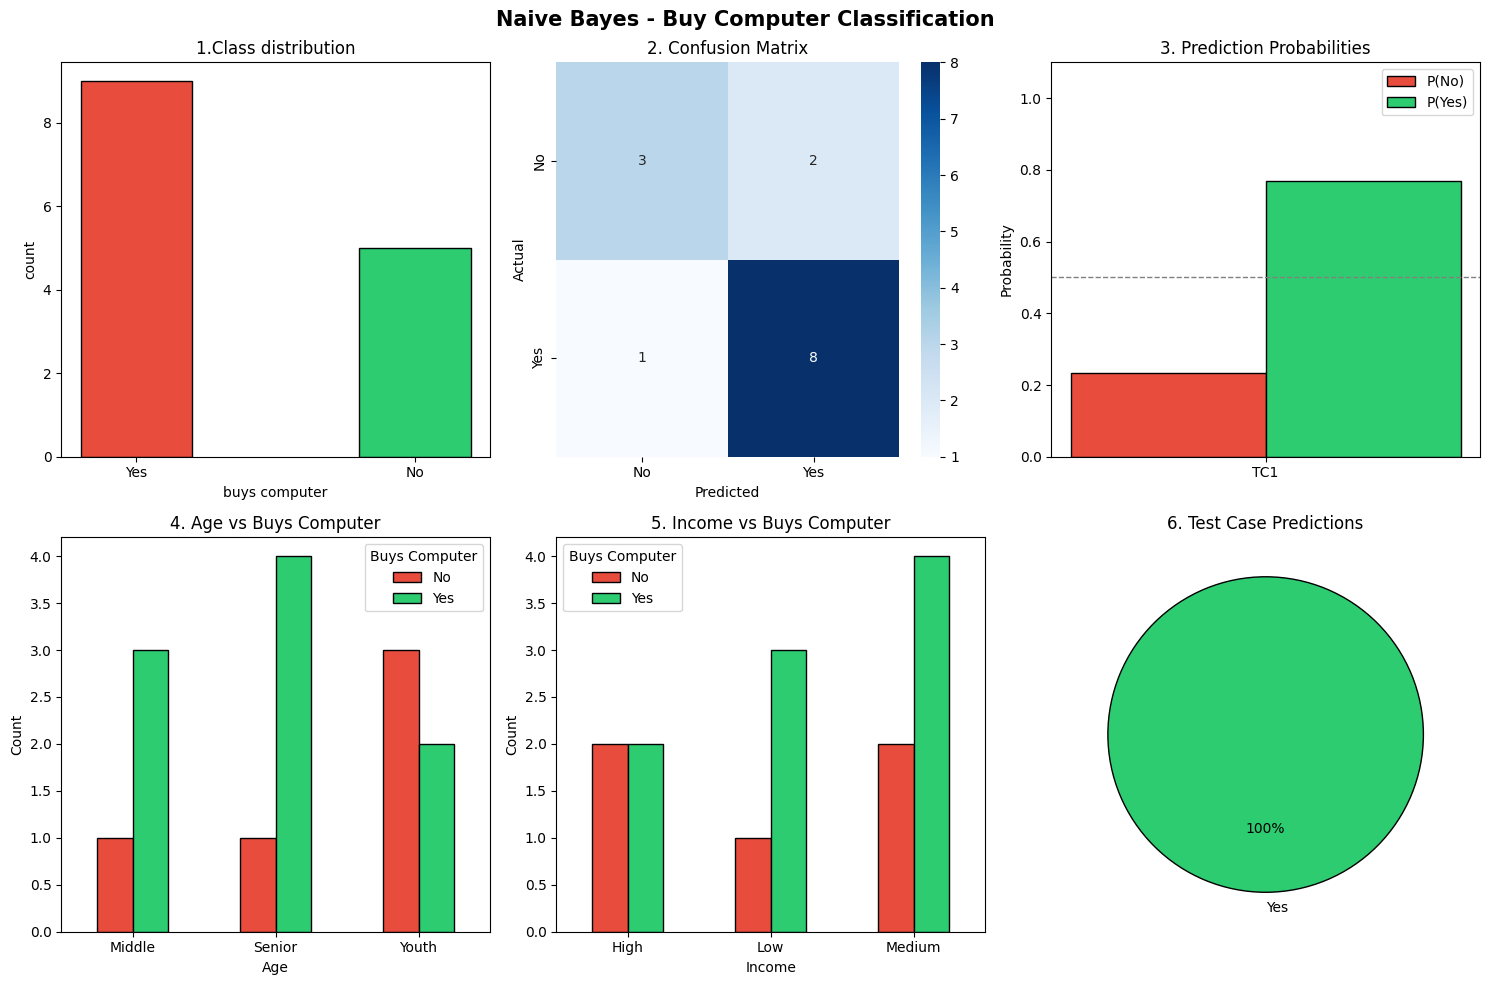

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle("Naive Bayes - Buy Computer Classification", fontsize=15, fontweight='bold')

# 1. Class Distribution
counts = df['BuysComputer'].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black', width=0.4)
axes[0, 0].set_title("1.Class distribution")
axes[0, 0].set_xlabel("buys computer")
axes[0, 0].set_ylabel("count")

# 2. Confusion Matrix
cm = confusion_matrix(y, model.predict(x))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'],
            yticklabels=['No', 'Yes'], ax=axes[0, 1])
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# 3. Prediction Probabilities (Grouped Bar)
test_cases = test
probs_no = [prob[0]]
probs_yes = [prob[1]]

tc_labels = [f"TC{i+1}" for i in range(len(test_cases))]
x_indices = np.arange(len(tc_labels))
w = 0.3

axes[0, 2].bar(x_indices - w/2, probs_no, w, label='P(No)',
              color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_indices + w/2, probs_yes, w, label='P(Yes)',
              color='#2ecc71', edgecolor='black')
axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_xticks(x_indices)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

# 4. Age vs BuysComputer
age_counts = df.groupby(['Age', 'BuysComputer']).size().unstack(fill_value=0)
age_counts.plot(
    kind='bar',
    ax=axes[1, 0],
    color=['#e74c3c', '#2ecc71'],
    edgecolor='black',
    rot=0
)
axes[1, 0].set_title("4. Age vs Buys Computer")
axes[1, 0].set_xlabel("Age")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(title="Buys Computer")

# 5. Income vs BuysComputer
inc_counts = df.groupby(['Income', 'BuysComputer']).size().unstack(fill_value=0)
inc_counts.plot(
    kind='bar',
    ax=axes[1, 1],
    color=['#e74c3c', '#2ecc71'],
    edgecolor='black',
    rot=0
)
axes[1, 1].set_title("5. Income vs Buys Computer")
axes[1, 1].set_xlabel("Income")
axes[1, 1].set_ylabel("Count")
axes[1, 1].legend(title="Buys Computer")

# 6. Pie Chart - Final Predictions
decoded_predictions = le['BuysComputer'].inverse_transform(test_predictions)
pred_counts = pd.Series(decoded_predictions).value_counts()
colors_pie = ['#2ecc71' if i == 'Yes' else '#e74c3c' for i in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, autopct='%1.0f%%',
              colors=colors_pie, startangle=90,
              wedgeprops={'edgecolor': 'black'})
axes[1, 2].set_title('6. Test Case Predictions')
plt.tight_layout()
plt.show()